<a href="https://colab.research.google.com/github/Likithakuppila/238w5a1211/blob/main/Yet_another_copy_of_Welcome_To_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Welcome to Colab!

In [ ]:
!pip install xgboost pandas scikit-learn matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 2000

df = pd.DataFrame({
    "amount": np.random.uniform(10, 50000, n),
    "hour": np.random.randint(0, 24, n),
    "transaction_type": np.random.choice(
        ["UPI", "Card", "Wallet", "NetBanking"], n
    ),
    "device_change": np.random.randint(0, 2, n),
    "location_mismatch": np.random.randint(0, 2, n)
})

# Synthetic labels for demonstration only
risk_score = (
    (df["amount"] > 30000).astype(int)
    + (df["hour"].isin([0, 1, 2, 3, 4])).astype(int)
    + df["device_change"]
    + df["location_mismatch"]
)

df["is_fraud"] = (
    (risk_score >= 3) & (np.random.rand(n) > 0.2)
).astype(int)

df.head()

,amount,hour,transaction_type,device_change,location_mismatch,is_fraud
0,18733.260541,6,NetBanking,1,1,0
1,47536.208177,2,UPI,1,0,1
2,36602.377151,22,Wallet,0,1,0
3,29936.937625,13,NetBanking,0,0,0
4,7809.371836,23,Card,1,1,0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)
from xgboost import XGBClassifier

X = df.drop("is_fraud", axis=1)
y = df["is_fraud"]

categorical_features = ["transaction_type"]
numerical_features = [
    "amount", "hour", "device_change", "location_mismatch"
]

preprocessor = ColumnTransformer([
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("numerical",
     SimpleImputer(strategy="median"),
     numerical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1600
Testing records: 400


In [ ]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("RANDOM FOREST RESULTS")
print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

RANDOM FOREST RESULTS
              precision    recall  f1-score   support

           0       0.98      0.97      0.97       340
           1       0.85      0.87      0.86        60

    accuracy                           0.96       400
   macro avg       0.91      0.92      0.92       400
weighted avg       0.96      0.96      0.96       400



In [ ]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_test)

print("XGBOOST RESULTS")
print(classification_report(
    y_test,
    xgb_predictions,
    zero_division=0
))

XGBOOST RESULTS
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       340
           1       0.86      0.93      0.90        60

    accuracy                           0.97       400
   macro avg       0.92      0.95      0.94       400
weighted avg       0.97      0.97      0.97       400



In [ ]:
results = []

for name, predictions in [
    ("Random Forest", rf_predictions),
    ("XGBoost", xgb_predictions)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

        Model  Accuracy  Precision  Recall  F1 Score
Random Forest    0.9575     0.8525  0.8667    0.8595
      XGBoost    0.9675     0.8615  0.9333    0.8960


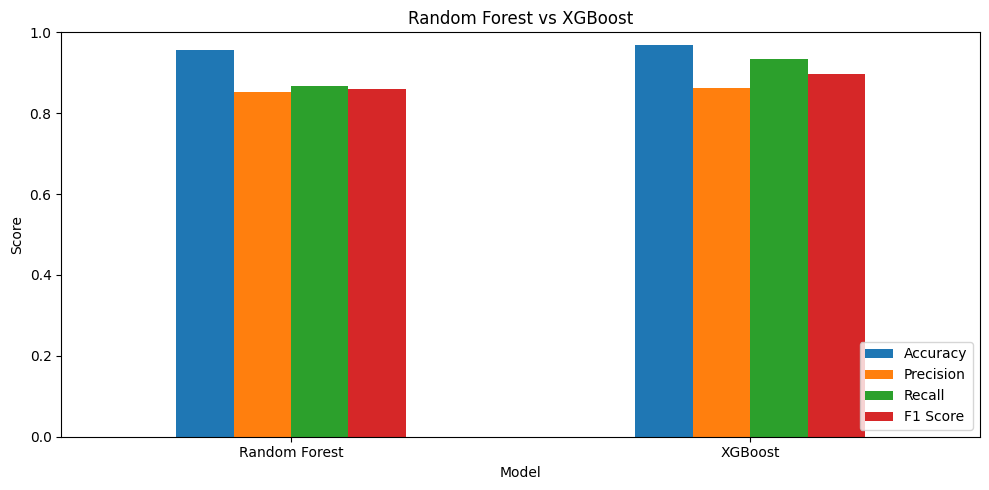

In [ ]:
import matplotlib.pyplot as plt

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Random Forest vs XGBoost")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
new_transaction = pd.DataFrame([{
    "amount": 45000,
    "hour": 2,
    "transaction_type": "UPI",
    "device_change": 1,
    "location_mismatch": 1
}])

for name, model in [
    ("Random Forest", rf_model),
    ("XGBoost", xgb_model)
]:
    prediction = model.predict(new_transaction)[0]

    result = (
        "Potentially Fraudulent"
        if prediction == 1
        else "Likely Legitimate"
    )

    print(f"{name}: {result}")

Random Forest: Potentially Fraudulent
XGBoost: Potentially Fraudulent


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving creditcard.csv to creditcard.csv


In [ ]:
import pandas as pd

df = pd.read_csv("creditcard.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFraud and Legitimate Transactions:")
print(df["Class"].value_counts())

Dataset Shape: (284807, 31)

First 5 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Fraud and Legitimate Transactions:
Class
0    284315
1       492
Name: count, dtype: int64


In [ ]:
print("Dataset Shape:", df.shape)

print("\nFraud and Legitimate Transactions:")
print(df["Class"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum().sum())

Dataset Shape: (284807, 31)

Fraud and Legitimate Transactions:
Class
0    284315
1       492
Name: count, dtype: int64

Missing Values:
0


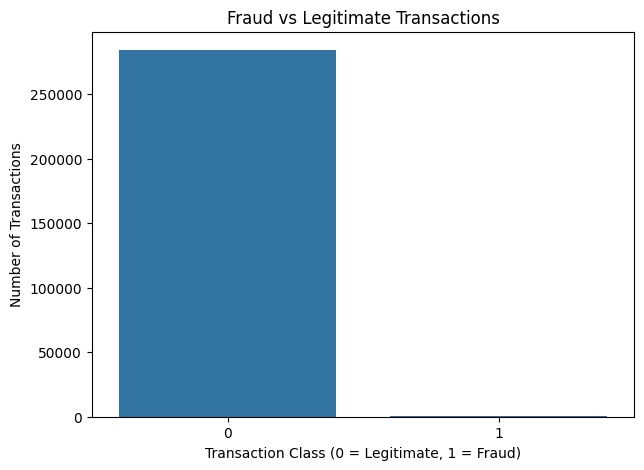

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(x="Class", data=df)

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()


In [ ]:

total_transactions = len(df)
fraud_transactions = (df["Class"] == 1).sum()
legitimate_transactions = (df["Class"] == 0).sum()

fraud_percentage = (fraud_transactions / total_transactions) * 100

print("Total Transactions:", total_transactions)
print("Fraud Transactions:", fraud_transactions)
print("Legitimate Transactions:", legitimate_transactions)
print("Fraud Percentage:", round(fraud_percentage, 2), "%")


Total Transactions: 284807
Fraud Transactions: 492
Legitimate Transactions: 284315
Fraud Percentage: 0.17 %


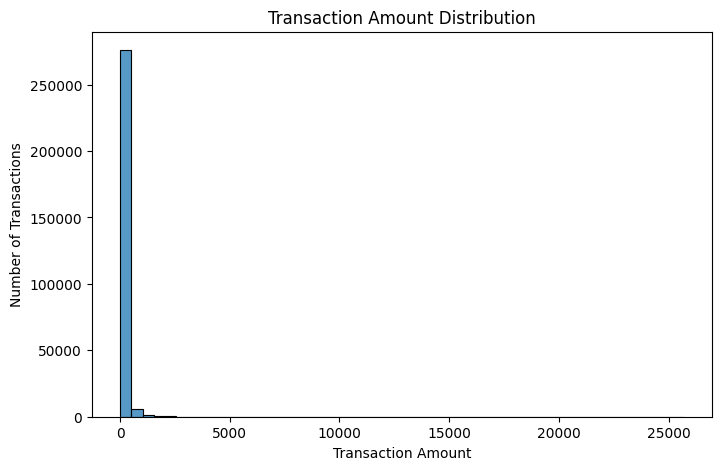

In [ ]:

plt.figure(figsize=(8, 5))

sns.histplot(df["Amount"], bins=50)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.show()


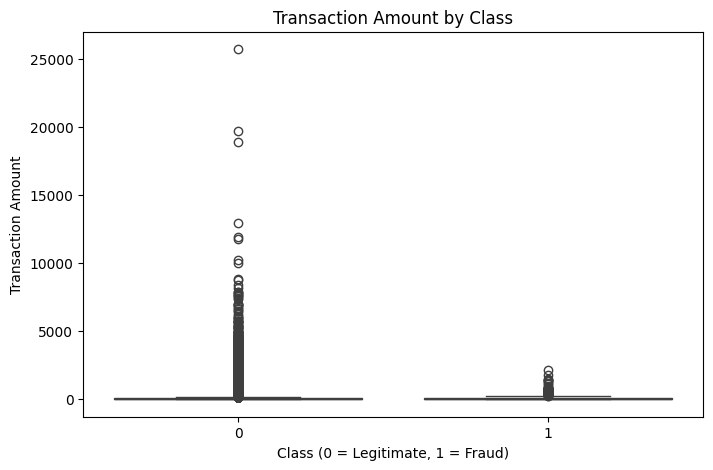

In [ ]:

plt.figure(figsize=(8, 5))

sns.boxplot(x="Class", y="Amount", data=df)

plt.title("Transaction Amount by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")

plt.show()


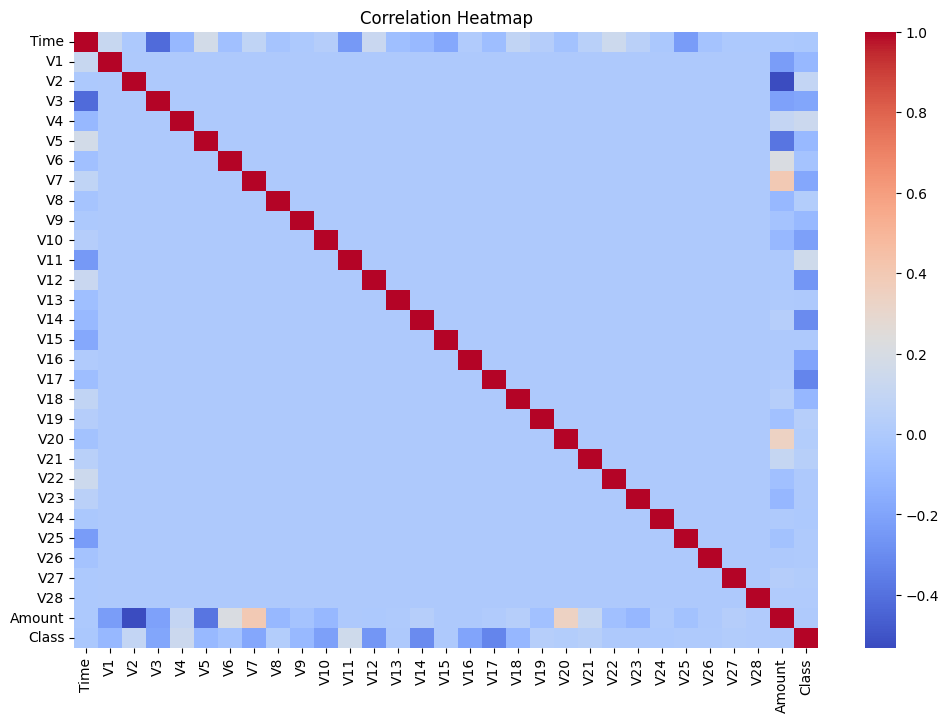

In [ ]:

plt.figure(figsize=(12, 8))

correlation = df.corr()

sns.heatmap(correlation, cmap="coolwarm", annot=False)

plt.title("Correlation Heatmap")
plt.show()


In [ ]:

print("===== CREDIT CARD FRAUD DETECTION DASHBOARD =====")

print("\nTotal Transactions:", len(df))
print("Fraud Transactions:", (df["Class"] == 1).sum())
print("Legitimate Transactions:", (df["Class"] == 0).sum())

print("Fraud Percentage:",
      round((df["Class"] == 1).mean() * 100, 2), "%")

print("Missing Values:", df.isnull().sum().sum())


===== CREDIT CARD FRAUD DETECTION DASHBOARD =====

Total Transactions: 284807
Fraud Transactions: 492
Legitimate Transactions: 284315
Fraud Percentage: 0.17 %
Missing Values: 0


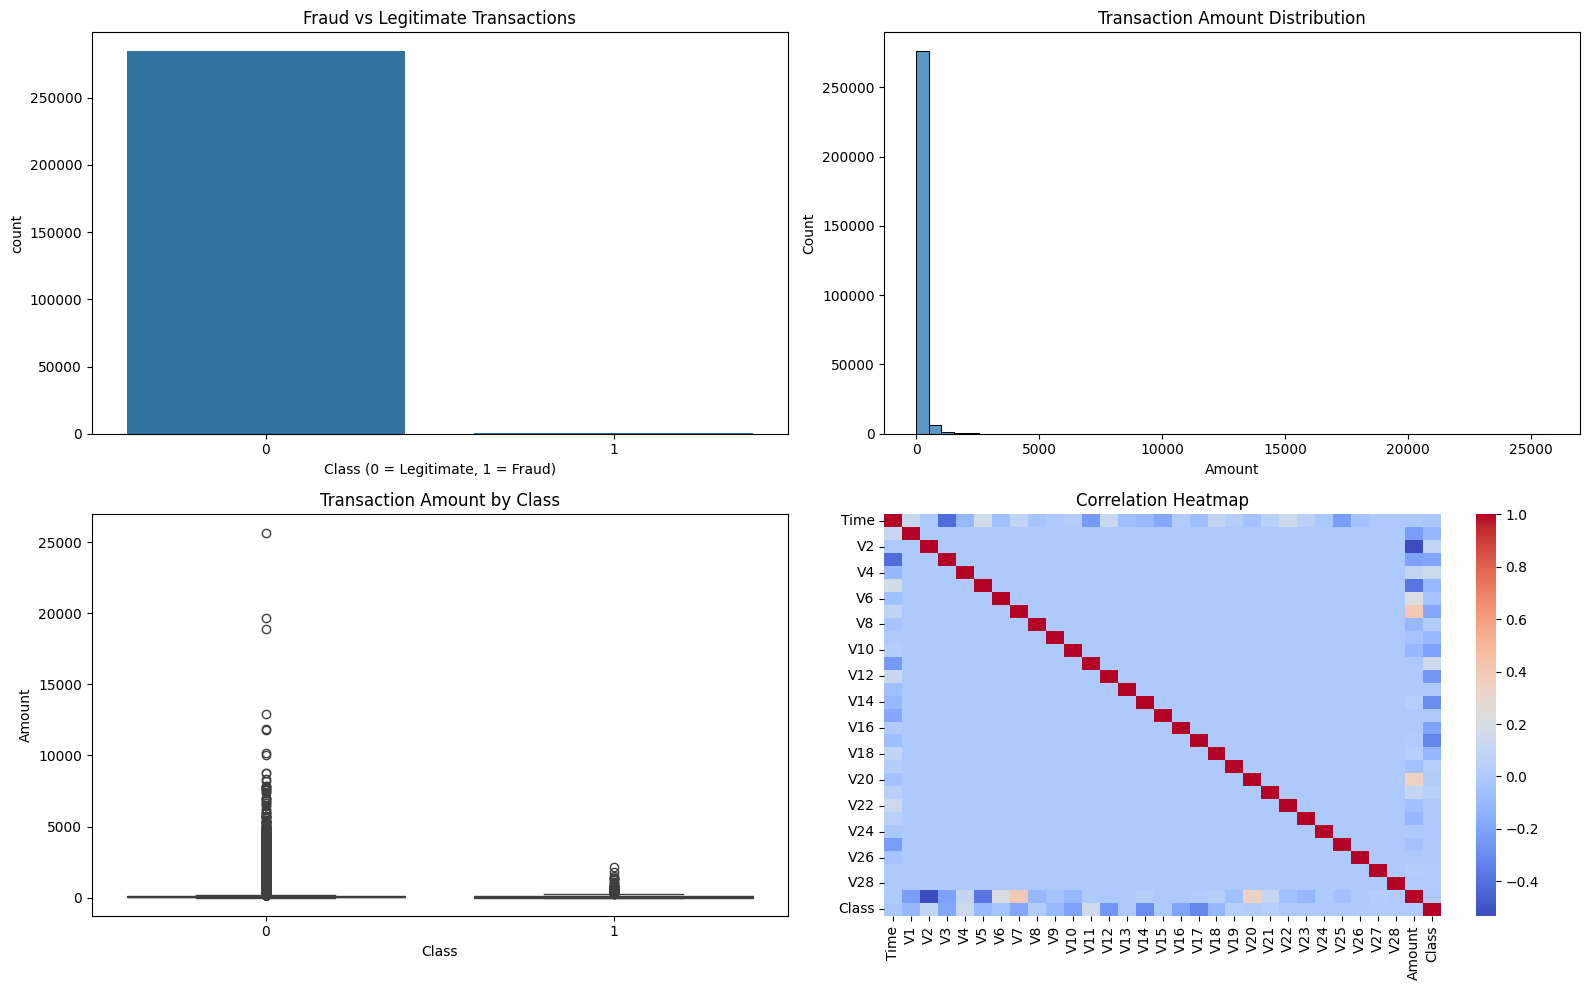

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Fraud vs Legitimate
sns.countplot(x="Class", data=df, ax=axes[0, 0])
axes[0, 0].set_title("Fraud vs Legitimate Transactions")
axes[0, 0].set_xlabel("Class (0 = Legitimate, 1 = Fraud)")

# 2. Transaction Amount Distribution
sns.histplot(df["Amount"], bins=50, ax=axes[0, 1])
axes[0, 1].set_title("Transaction Amount Distribution")

# 3. Transaction Amount by Class
sns.boxplot(x="Class", y="Amount", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Transaction Amount by Class")

# 4. Correlation Heatmap
sns.heatmap(df.corr(), cmap="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("Correlation Heatmap")

plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import ipywidgets as widgets
from IPython.display import display, HTML

data = df.copy()
data["Amount"] = pd.to_numeric(data["Amount"], errors="coerce")
data = data.dropna(subset=["Class", "Amount"])

class_filter = widgets.Dropdown(
    options=[
        ("All Transactions", "All"),
        ("Legitimate Transactions (0)", 0),
        ("Fraud Transactions (1)", 1)
    ],
    value="All",
    description="Class:"
)

output = widgets.Output()

def update_dashboard(change=None):
    selected = class_filter.value

    if selected == "All":
        filtered = data
    else:
        filtered = data[data["Class"] == selected]

    total = len(filtered)
    fraud = int((filtered["Class"] == 1).sum())
    legitimate = int((filtered["Class"] == 0).sum())
    percentage = fraud / total * 100 if total else 0

    with output:
        output.clear_output(wait=True)

        display(HTML(f"""
        <div style="background:#172554;color:white;padding:20px;
                    border-radius:12px;">
          <h2>Credit Card Fraud Detection Dashboard</h2>
          <p>Selected Class: {selected}</p>
        </div>
        <div style="display:flex;flex-wrap:wrap;gap:12px;
                    margin-top:15px;">
          <div style="background:#e0f2fe;padding:18px;border-radius:10px;">
            <b>Total Transactions</b><h2>{total:,}</h2>
          </div>
          <div style="background:#fee2e2;padding:18px;border-radius:10px;">
            <b>Fraud Transactions</b><h2>{fraud:,}</h2>
          </div>
          <div style="background:#dcfce7;padding:18px;border-radius:10px;">
            <b>Legitimate Transactions</b><h2>{legitimate:,}</h2>
          </div>
          <div style="background:#f3e8ff;padding:18px;border-radius:10px;">
            <b>Fraud Percentage</b><h2>{percentage:.2f}%</h2>
          </div>
        </div>
        """))

        display(HTML("<h3>Transaction Summary</h3>"))
        display(filtered["Class"].value_counts().rename(
            index={0: "Legitimate", 1: "Fraud"}
        ).to_frame("Number of Transactions"))

class_filter.observe(update_dashboard, names="value")

display(class_filter)
display(output)
update_dashboard()


Dropdown(description='Class:', options=(('All Transactions', 'All'), ('Legitimate Transactions (0)', 0), ('Fra…

Output()

In [ ]:

%%writefile requirements.txt
streamlit
pandas
plotly


Writing requirements.txt


In [ ]:

%%writefile app.py
import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(
    page_title="Credit Card Fraud Detection",
    page_icon="💳",
    layout="wide"
)

st.title("💳 Credit Card Fraud Detection Dashboard")
st.write("Interactive Transaction Analysis")

uploaded_file = st.file_uploader(
    "Upload your creditcard.csv dataset",
    type=["csv"]
)

if uploaded_file is not None:
    df = pd.read_csv(uploaded_file)

    if not {"Class", "Amount"}.issubset(df.columns):
        st.error("Dataset must contain Class and Amount columns.")
        st.stop()

    df["Amount"] = pd.to_numeric(
        df["Amount"], errors="coerce"
    )
    df = df.dropna(subset=["Class", "Amount"])

    st.sidebar.header("Filters")

    transaction_type = st.sidebar.selectbox(
        "Transaction Type",
        ["All", "Legitimate (0)", "Fraud (1)"]
    )

    max_amount = max(float(df["Amount"].max()), 1.0)

    amount_range = st.sidebar.slider(
        "Amount Range",
        min_value=0.0,
        max_value=max_amount,
        value=(0.0, max_amount)
    )

    filtered = df[
        df["Amount"].between(
            amount_range[0], amount_range[1]
        )
    ]

    if transaction_type == "Legitimate (0)":
        filtered = filtered[filtered["Class"] == 0]
    elif transaction_type == "Fraud (1)":
        filtered = filtered[filtered["Class"] == 1]

    total = len(filtered)
    fraud = int((filtered["Class"] == 1).sum())
    legitimate = int((filtered["Class"] == 0).sum())
    fraud_pct = fraud / total * 100 if total else 0

    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Total Transactions", f"{total:,}")
    c2.metric("Fraud Transactions", f"{fraud:,}")
    c3.metric("Legitimate Transactions", f"{legitimate:,}")
    c4.metric("Fraud Percentage", f"{fraud_pct:.2f}%")

    if total:
        counts = (
            filtered["Class"]
            .map({0: "Legitimate", 1: "Fraud"})
            .value_counts()
            .rename_axis("Transaction Type")
            .reset_index(name="Count")
        )

        st.subheader("Fraud vs Legitimate Transactions")
        st.plotly_chart(
            px.bar(counts, x="Transaction Type", y="Count",
                   color="Transaction Type"),
            use_container_width=True
        )

        st.subheader("Transaction Amount Distribution")
        chart_data = filtered.sample(
            n=min(10000, total), random_state=42
        )
        st.plotly_chart(
            px.histogram(
                chart_data, x="Amount", color="Class",
                nbins=40
            ),
            use_container_width=True
        )

        st.subheader("Transaction Amount by Class")
        st.plotly_chart(
            px.box(chart_data, x="Class", y="Amount"),
            use_container_width=True
        )
    else:
        st.warning("No transactions match these filters.")

else:
    st.info("Upload your creditcard.csv file to begin.")


Writing app.py


In [ ]:

from google.colab import files

files.download("app.py")
files.download("requirements.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

# Reload the dataset to ensure 'df' is defined
df = pd.read_csv("creditcard.csv")

print(df.shape)
print(df.columns.tolist())
print(df.head())

NameError: name 'df' is not defined

In [ ]:
import pandas as pd

df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print(df.shape)
print(df.columns.tolist())

FileNotFoundError: [Errno 2] No such file or directory: 'creditcard.csv'

In [ ]:
import os
print(os.listdir())

['.config', 'sample_data']


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving creditcard.csv to creditcard.csv


In [ ]:
import pandas as pd

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print(df.shape)
print(df.columns.tolist())

Dataset loaded successfully!
(284807, 31)
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [ ]:
import pandas as pd

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

Dataset loaded successfully!
Shape: (284807, 31)
Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   


In [ ]:
print(df.isnull().sum().sum())

0


In [ ]:
print(df["Class"].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [ ]:

!pip install -q xgboost


In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from xgboost import XGBClassifier

# Separate features and target
X = df.drop(columns=["Class"])
y = df["Class"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Calculate class imbalance ratio for XGBoost
negative = int((y_train == 0).sum())
positive = int((y_train == 1).sum())
ratio = negative / positive

# Define models
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=150,
        max_depth=5,
        learning_rate=0.1,
        scale_pos_weight=ratio,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

# Train and evaluate both models
results = []

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy (%)": round(
            accuracy_score(y_test, predictions) * 100, 2
        ),
        "Precision (%)": round(
            precision_score(y_test, predictions, zero_division=0) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_test, predictions, zero_division=0) * 100, 2
        ),
        "F1 Score (%)": round(
            f1_score(y_test, predictions, zero_division=0) * 100, 2
        )
    })

    print(f"\n{name} Classification Report:")
    print(classification_report(
        y_test, predictions,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    ))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

comparison = pd.DataFrame(results)
print("\nMODEL COMPARISON")
print(comparison.to_string(index=False))



Training Random Forest...

Random Forest Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.96      0.74      0.84        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
[[56861     3]
 [   25    73]]

Training XGBoost...

XGBoost Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.74      0.84      0.78        98

    accuracy                           1.00     56962
   macro avg       0.87      0.92      0.89     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
[[56835    29]
 [   16    82]]

MODEL COMPARISON
        Model  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)
Random Forest         99.95          96.05 

In [ ]:
import joblib

joblib.dump(models["Random Forest"], "random_forest_model.pkl")
joblib.dump(models["XGBoost"], "xgboost_model.pkl")

print("Both models saved successfully!")

Both models saved successfully!


In [ ]:
from google.colab import files

files.download("random_forest_model.pkl")
files.download("xgboost_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Dataset loaded:", "df" in globals())

if "df" in globals():
    print("Dataset shape:", df.shape)
    print("Columns:", df.columns.tolist())
else:
    print("Dataset is not loaded. Run the dataset loading cell first.")

Dataset loaded: True
Dataset shape: (284807, 31)
Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [ ]:
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# 1. Prepare dataset
X = df.drop(columns=["Class"])
y = df["Class"].astype(int)

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest... Please wait.")

rf_model.fit(X_train, y_train)

print("Training completed!")

# 4. Evaluate model
y_pred = rf_model.predict(X_test)

print("\nModel Performance:")
print(classification_report(y_test, y_pred, zero_division=0))

# 5. Check predictions and probabilities
sample_transactions = X_test.iloc[:10]

predictions = rf_model.predict(sample_transactions)
probabilities = rf_model.predict_proba(sample_transactions)

print("\n--- Prediction and Probability Check ---")

fraud_index = list(rf_model.classes_).index(1)

for i in range(len(sample_transactions)):
    fraud_probability = probabilities[i][fraud_index]

    print(
        f"Transaction {i + 1}: "
        f"Prediction = {predictions[i]}, "
        f"Fraud Probability = {fraud_probability * 100:.6f}%, "
        f"Actual Class = {y_test.loc[sample_transactions.index[i]]}"
    )

# 6. Save the newly trained model
joblib.dump(rf_model, "random_forest_model.pkl")

print("\nNew Random Forest model saved successfully!")

Training Random Forest... Please wait.
Training completed!

Model Performance:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.74      0.84        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962


--- Prediction and Probability Check ---
Transaction 1: Prediction = 0, Fraud Probability = 0.000000%, Actual Class = 0
Transaction 2: Prediction = 0, Fraud Probability = 0.000000%, Actual Class = 0
Transaction 3: Prediction = 0, Fraud Probability = 0.000000%, Actual Class = 0
Transaction 4: Prediction = 0, Fraud Probability = 0.000000%, Actual Class = 0
Transaction 5: Prediction = 0, Fraud Probability = 0.000000%, Actual Class = 0
Transaction 6: Prediction = 0, Fraud Probability = 0.000000%, Actual Class = 0
Transaction 7: Prediction = 0, Fraud Probability = 0.000000%, Actual Class = 0

In [ ]:
from google.colab import files

files.download("random_forest_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<div class="markdown-google-sans">
  <h2>What is Colab?</h2>
</div>

Colab, or "Colaboratory", allows you to write and execute Python in your browser, with
- Zero configuration required
- Access to GPUs free of charge
- Easy sharing

Whether you're a **student**, a **data scientist** or an **AI researcher**, Colab can make your work easier. Watch [Introduction to Colab](https://www.youtube.com/watch?v=inN8seMm7UI) or [Colab Features You May Have Missed](https://www.youtube.com/watch?v=rNgswRZ2C1Y) to learn more, or just get started below!

<div class="markdown-google-sans">

## **Getting started**
</div>

The document you are reading is not a static web page, but an interactive environment called a **Colab notebook** that lets you write and execute code.

For example, here is a **code cell** with a short Python script that computes a value, stores it in a variable, and prints the result:

In [ ]:
seconds_in_a_day = 24 * 60 * 60
seconds_in_a_day

86400

To execute the code in the above cell, select it with a click and then either press the play button to the left of the code, or use the keyboard shortcut "Command/Ctrl+Enter". To edit the code, just click the cell and start editing.

Variables that you define in one cell can later be used in other cells:

In [ ]:
seconds_in_a_week = 7 * seconds_in_a_day
seconds_in_a_week

604800

Colab notebooks allow you to combine **executable code** and **rich text** in a single document, along with **images**, **HTML**, **LaTeX** and more. When you create your own Colab notebooks, they are stored in your Google Drive account. You can easily share your Colab notebooks with co-workers or friends, allowing them to comment on your notebooks or even edit them. To learn more, see [Overview of Colab](/notebooks/basic_features_overview.ipynb). To create a new Colab notebook you can use the File menu above, or use the following link: [create a new Colab notebook](http://colab.research.google.com#create=true).

Colab notebooks are Jupyter notebooks that are hosted by Colab. To learn more about the Jupyter project, see [jupyter.org](https://www.jupyter.org).

## Google Colab is available in VS Code!
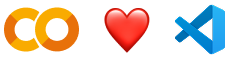

Try the new [Google Colab extension](https://marketplace.visualstudio.com/items?itemName=Google.colab) for Visual Studio Code. You can get up and running in just a few clicks:

*  In VS Code, open the ***Extensions*** view and search for 'Google Colab' to install.
*  Open the kernel selector by creating or opening any `.ipynb` notebook file in your local workspace and either running a cell or clicking the ***Select Kernel*** button in the top right.
*  Click ***Colab*** and then select your desired runtime, sign in with your Google account, and you're all set!

See more details in our [announcement blog here](https://developers.googleblog.com/google-colab-is-coming-to-vs-code).

## Access popular AI models via Google-Colab-AI Without an API Key
All users have access to most popular LLMs via the `google-colab-ai` Python library, and paid users have access to a wider selection of models. For more details, refer to the [getting started with google colab ai](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/Getting_started_with_google_colab_ai.ipynb).



In [ ]:
from google.colab import ai
response = ai.generate_text("What is the capital of France?")

## Explore the Gemini API
The Gemini API gives you access to Gemini models created by Google DeepMind. Gemini models are built from the ground up to be multimodal, so you can reason seamlessly across text, images, code, and audio.

**How to get started?**
*  Go to [Google AI Studio](https://aistudio.google.com/) and log in with your Google account.
*  [Create an API key](https://aistudio.google.com/app/apikey).
* Use a quickstart for [Python](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started.ipynb), or call the REST API using [curl](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/rest/Prompting_REST.ipynb).

**Discover Gemini's advanced capabilities**
*  Play with Gemini [multimodal outputs](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Image-out.ipynb), mixing text and images in an iterative way.
*  Discover the [multimodal Live API](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_LiveAPI.ipynb ) (demo [here](https://aistudio.google.com/live)).
*  Learn how to [analyze images and detect items in your pictures](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Spatial_understanding.ipynb") using Gemini (bonus, there's a [3D version](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Spatial_understanding_3d.ipynb) as well!).
*  Unlock the power of [Gemini thinking model](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_thinking.ipynb), capable of solving complex task with its inner thoughts.
      
**Explore complex use cases**
*  Use [Gemini grounding capabilities](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Search_grounding_for_research_report.ipynb) to create a report on a company based on what the model can find on internet.
*  Extract [invoices and form data from PDF](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Pdf_structured_outputs_on_invoices_and_forms.ipynb) in a structured way.
*  Create [illustrations based on a whole book](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Book_illustration.ipynb) using Gemini large context window and Imagen.

To learn more, check out the [Gemini cookbook](https://github.com/google-gemini/cookbook) or visit the [Gemini API documentation](https://ai.google.dev/docs/).


Colab now has AI features powered by [Gemini](https://gemini.google.com). The video below provides information on how to use these features, whether you're new to Python, or a seasoned veteran.

<center>
  <a href="https://www.youtube.com/watch?v=V7RXyqFUR98" target="_blank">
  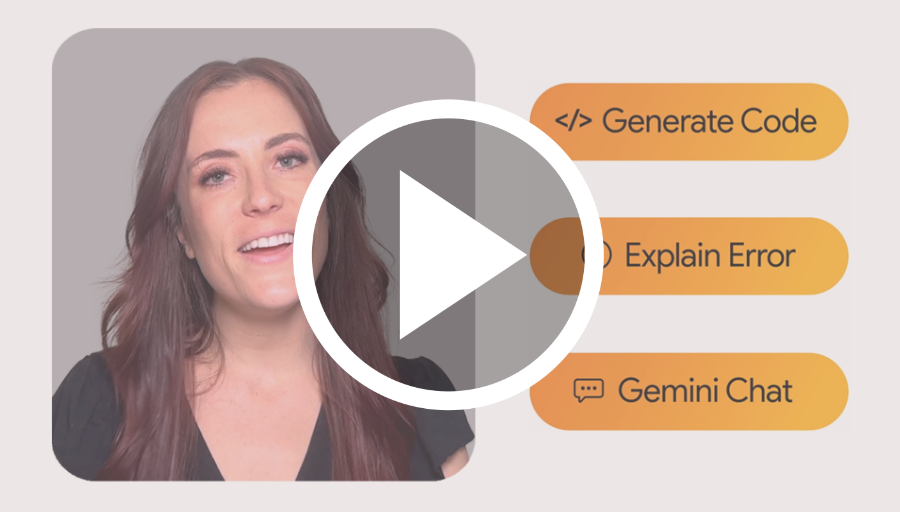
  </a>
</center>

<div class="markdown-google-sans">

## Data science
</div>

With Colab you can harness the full power of popular Python libraries to analyze and visualize data. The code cell below uses **numpy** to generate some random data, and uses **matplotlib** to visualize it. To edit the code, just click the cell and start editing.

You can import your own data into Colab notebooks from your Google Drive account, including from spreadsheets, as well as from Github and many other sources. To learn more about importing data, and how Colab can be used for data science, see the links below under [Working with Data](#working-with-data).

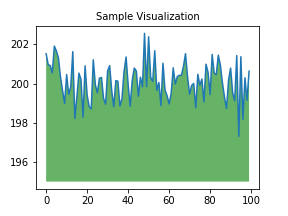

In [ ]:
import numpy as np
import IPython.display as display
from matplotlib import pyplot as plt
import io
import base64

ys = 200 + np.random.randn(100)
x = [x for x in range(len(ys))]

fig = plt.figure(figsize=(4, 3), facecolor='w')
plt.plot(x, ys, '-')
plt.fill_between(x, ys, 195, where=(ys > 195), facecolor='g', alpha=0.6)
plt.title("Sample Visualization", fontsize=10)

data = io.BytesIO()
plt.savefig(data)
image = F"data:image/png;base64,{base64.b64encode(data.getvalue()).decode()}"
alt = "Sample Visualization"
display.display(display.Markdown(F"""![{alt}]({image})"""))
plt.close(fig)

Colab notebooks execute code on Google's cloud servers, meaning you can leverage the power of Google hardware, including [GPUs and TPUs](#using-accelerated-hardware), regardless of the power of your machine. All you need is a browser.

For example, if you find yourself waiting for **pandas** code to finish running and want to go faster, you can switch to a GPU Runtime and use libraries like [RAPIDS cuDF](https://rapids.ai/cudf-pandas) that provide zero-code-change acceleration.

To learn more about accelerating pandas on Colab, see the [10 minute guide](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_colab_demo.ipynb) or
 [US stock market data analysis demo](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_stocks_demo.ipynb).

<div class="markdown-google-sans">

## Machine learning
</div>

With Colab you can import an image dataset, train an image classifier on it, and evaluate the model, all in just [a few lines of code](https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/quickstart/beginner.ipynb).

Colab is used extensively in the machine learning community with applications including:
- Getting started with TensorFlow
- Developing and training neural networks
- Experimenting with TPUs
- Disseminating AI research
- Creating tutorials

To see sample Colab notebooks that demonstrate machine learning applications, see the [machine learning examples](#machine-learning-examples) below.

<div class="markdown-google-sans">

## More Resources

### Working with Notebooks in Colab

</div>

- [Overview of Colab](/notebooks/basic_features_overview.ipynb)
- [Guide to Markdown](/notebooks/markdown_guide.ipynb)
- [Importing libraries and installing dependencies](/notebooks/snippets/importing_libraries.ipynb)
- [Saving and loading notebooks in GitHub](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/colab-github-demo.ipynb)
- [Interactive forms](/notebooks/forms.ipynb)
- [Interactive widgets](/notebooks/widgets.ipynb)

<div class="markdown-google-sans">

<a name="working-with-data"></a>
### Working with Data
</div>

- [Loading data: Drive, Sheets, and Google Cloud Storage](/notebooks/io.ipynb)
- [Charts: visualizing data](/notebooks/charts.ipynb)
- [Getting started with BigQuery](/notebooks/bigquery.ipynb)

<div class="markdown-google-sans">

### Machine Learning

<div>

These are a few of the notebooks related to Machine Learning, including Google's online Machine Learning course. See the [full course website](https://developers.google.com/machine-learning/crash-course/) for more.
- [Intro to Pandas DataFrame](https://colab.research.google.com/github/google/eng-edu/blob/main/ml/cc/exercises/pandas_dataframe_ultraquick_tutorial.ipynb)
- [Intro to RAPIDS cuDF to accelerate pandas](https://nvda.ws/rapids-cudf)
- [Getting Started with cuML's accelerator mode](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cuml_sklearn_colab_demo.ipynb)

<div class="markdown-google-sans">

<a name="using-accelerated-hardware"></a>
### Using Accelerated Hardware
</div>

- [Train a CNN to classify handwritten digits on the MNIST dataset using Flax NNX API](https://colab.research.google.com/github/google/flax/blob/main/docs_nnx/mnist_tutorial.ipynb)
- [Train a Vision Transformer (ViT) for image classification with JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_Vision_transformer.ipynb)
- [Text classification with a transformer language model using JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_transformer_text_classification.ipynb)

<div class="markdown-google-sans">

<a name="machine-learning-examples"></a>

### Featured examples

</div>

- [Train a miniGPT language model with JAX AI Stack](https://docs.jaxstack.ai/en/latest/JAX_for_LLM_pretraining.html)
- [LoRA/QLoRA finetuning for LLM using Tunix](https://github.com/google/tunix/blob/main/examples/qlora_gemma.ipynb)
- [Parameter-efficient fine-tuning of Gemma with LoRA and QLoRA](https://keras.io/examples/keras_recipes/parameter_efficient_finetuning_of_gemma_with_lora_and_qlora/)
- [Loading Hugging Face Transformers Checkpoints](https://keras.io/keras_hub/guides/hugging_face_keras_integration/)
- [8-bit Integer Quantization in Keras](https://keras.io/guides/int8_quantization_in_keras/)
- [Float8 training and inference with a simple Transformer model](https://keras.io/examples/keras_recipes/float8_training_and_inference_with_transformer/)
- [Pretraining a Transformer from scratch with KerasHub](https://keras.io/keras_hub/guides/transformer_pretraining/)
- [Simple MNIST convnet](https://keras.io/examples/vision/mnist_convnet/)
- [Image classification from scratch using Keras 3](https://keras.io/examples/vision/image_classification_from_scratch/)
- [Image Classification with KerasHub](https://keras.io/keras_hub/guides/classification_with_keras_hub/)
